# ICT-42e — Témoin négatif du contrôle apparié : aire signée, seuil sur l'aire, sham de discrétisation

**Réponse aux 3 findings de l'audit #17183 sur ICT-42d** (lui-même réponse à la limite 2 d'ICT-42c, #20253). Le carnet **ICT-42d** mesure une divergence locale $D(t)$ entre une trace **rampée** (inoculation croissante puis décroissante, profil triangulaire) et une trace **constante** appariée par position : à chaque token, le $\alpha$ constant le plus proche du $\alpha(t)$ de la rampe. La différence $\Delta(t) = D_{ramp}(t) - D_{const,\alpha^*}(t)$ est la signature d'histoire à position fixée, et son aire devait trancher **MEMOIRE** (la rampe laisse une empreinte qu'un $\alpha$ instantané n'explique pas) contre **POSITION** (tout est expliqué par la position et le $\alpha$ instantané).

L'audit a montré que l'instrument ne pouvait pas rendre ce verdict :

1. l'aire publiée était $\mathrm{Aire}(|\Delta|)$ — positive par construction, la branche « POSITION » était **morte** ;
2. le $\Delta$ **signé** était perdu — et il est **négatif** ($D_{const} > D_{ramp}$, mesuré $-0{,}6280$ / $-0{,}0985$ aux deux échelles) ;
3. le seuil était posé sur une statistique **ponctuelle** (SEM de la divergence moyenne à $\alpha = 0{,}5$) et comparé à une **aire** ;
4. la signification n'était pas évaluée prompt par prompt.

**Ce carnet corrige l'instrument et installe le témoin négatif GPU-free** : le verdict est recalculé sur l'aire **signée par prompt**, seuilée par la distribution **des aires d'un sham** (une paire de traces **constantes** adjacentes soumise au même mapping $\alpha^*$). Le témoin GPU à proprement parler — un clamp **réinitialisé à chaque passe**, pour lequel aucune passe ne voit l'inoculation d'une autre passe — est attendu du lot GPU 2 en cours : sa cellule de branchement est **optionnelle** et ne bloque pas la livraison.

## Protocole — repris à l'identique d'ICT-42d

Rien ne se rediscute : même convention d'$\alpha$, même divergence locale, même horizon de prompts.

| Élément | Définition (ICT-42d, reprise à l'identique) |
|---|---|
| Divergence locale | $D(z, z_0; t) = \|x_a(t) - x_0(t)\|_1 / \|x_0(t)\|_1$ sur la reconstruction dense du top-k SAE ($k = 50$), contre la référence $\alpha = 0$ du pilote |
| Mapping $\alpha^*(t)$ | étage de $\{0, 0{,}25, 0{,}5, 0{,}75, 1\}$ le plus proche de $\alpha(t)$ (erreur $\le \pm 0{,}125$) |
| Position normalisée | $s = t/T$ par prompt, grille $S = 100$, projection par index le plus proche |
| Aire | intégrale trapézoïdale sur $s \in [0, 1]$ — **signée** ici, là où 42d intégrait $|\Delta|$ |
| Échelles | Qwen3-1.7B-Base (couche 27/28) et Qwen3.5-2B-Base (couche 23/24), panel clamp16 partagé, 20 prompts |
| Horizon de prompts | le prompt set du pilote (20 prompts, identique rampe/const, vérifié par assertion) |


## Garde-fous d'honnêteté (à lire avant les résultats)

1. **Traces existantes, aucun run GPU.** Ce carnet consomme uniquement les traces déjà committées (`traces/` : rampes `inoc_hyst_*` et constantes `inoc_*_s{alpha}` du pilote). Aucun lancement GPU, aucune extraction.
2. **Définitions reprises, pas redisputées.** `local_divergence` et `match_alpha` sont recopiées à l'identique des cellules 7-8 d'ICT-42d ; la grille $S = 100$, la projection $s = t/T$ et l'aire trapézoïdale de sa cellule 12 ; le facteur 1,96 de sa cellule 14. Seul change **ce qui est intégré** (le $\Delta$ signé et non sa valeur absolue) et **ce qui seuille** (la SEM des aires et non celle d'une divergence ponctuelle).
3. **Le signe est publié.** L'audit (finding 2) a mesuré un $\Delta$ négatif ; ce carnet publie l'aire signée à côté de l'aire non signée, et interprète le signe — la grille de lecture d'ICT-42d (« $\Delta$ positif = mémoire ») était inversée par rapport à la mesure.
4. **Le seuil seuille la statistique testée.** La distribution nulle est celle **des aires par prompt d'un sham** : la même pipeline appliquée à des traces purement constantes, où aucune histoire n'est possible. Ce que le sham produit, c'est l'aire fabriquée par la seule discrétisation de $\alpha^*$.
5. **Le témoin GPU ne bloque pas.** Les branches isolées (`inocneg_*`, clamp réinitialisé à chaque passe) sont attendues du lot GPU 2 : la cellule de branchement les cherche, liste ce qu'elle trouve, et rend la main sans conclure tant qu'elles sont absentes.


In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
from ict.sae_traces import ramp_alpha  # verite de reference du profil triangulaire (42d, cellule 3)

TRACES = Path("traces")
CYCLES = 2
PEAK = 1.0
ALPHA_DISCRET = np.array([0.0, 0.25, 0.5, 0.75, 1.0])  # etages const disponibles (42d, cellule 3)
ECHELLES = {
    "Qwen3-1.7B-Base": {"slug": "qwen3-17b-base", "n_layers": 28},
    "Qwen3.5-2B-Base": {"slug": "qwen35-2b-base", "n_layers": 24},
}
S = 100  # grille de position normalisee (42d, cellule 8)
s_grid = np.arange(S) / S

# --- Fonctions reprises A L'IDENTIQUE d'ICT-42d (cellules 3 et 7) ---

def load_meta(path):
    return json.loads(str(np.load(path, allow_pickle=False)["__meta__"]))

def prompt_keys(z):
    return sorted({k.rsplit("__", 1)[0] for k in z.files if k.endswith("__topk_ids")})

def trace_path_const(slug, n, alpha):
    """Chemin d'une trace const-alpha (42d, cellule 3) : a alpha=1.0 le suffixe _s{n}
    est omis (convention trace_filename de ict.sae_traces)."""
    if abs(alpha - 1.0) < 1e-9:
        return TRACES / f"inoc_{slug}_layer{n - 1}of{n}_trained_clamp16.npz"
    return TRACES / f"inoc_{slug}_layer{n - 1}of{n}_trained_clamp16_s{alpha:g}.npz"

def trace_path_ramp(slug, n):
    return TRACES / f"inoc_hyst_{slug}_layer{n - 1}of{n}_trained_clamp16_ramp{CYCLES}p1.npz"

def local_divergence(z, z0, key, d_sae):
    """||x_a(t) - x_0(t)||_1 / ||x_0(t)||_1 sur le top-k dense, prompt key.
    (Reprise byte-identique de la cellule 7 d'ICT-42d, elle-meme reprise de 42c.)"""
    ids0 = z0[f"{key}__topk_ids"].astype(np.int64)
    idsa = z[f"{key}__topk_ids"].astype(np.int64)
    v0 = z0[f"{key}__topk_vals"].astype(np.float32)
    va = z[f"{key}__topk_vals"].astype(np.float32)
    T = min(ids0.shape[0], idsa.shape[0])
    div = np.zeros(T, dtype=np.float64)
    for t in range(T):
        x0 = np.zeros(d_sae, dtype=np.float32)
        xa = np.zeros(d_sae, dtype=np.float32)
        x0[ids0[t]] = v0[t]
        xa[idsa[t]] = va[t]
        div[t] = np.abs(xa - x0).sum() / (np.abs(x0).sum() + 1e-9)
    return div

def match_alpha(alpha_continuous):
    """Indice de l'alpha discret le plus proche + erreur d'arrondi (42d, cellule 7).
    Erreur bornee a +/-0.125 : la demi-distance entre deux etages adjacents."""
    idx = int(np.argmin(np.abs(ALPHA_DISCRET - alpha_continuous)))
    return ALPHA_DISCRET[idx], float(ALPHA_DISCRET[idx] - alpha_continuous)

# --- Inventaire + contrat + champs par prompt ---

rows = []
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    p_ramp = trace_path_ramp(cfg["slug"], n)
    assert p_ramp.exists(), f"trace rampe absente : {p_ramp}"
    z_ramp = np.load(p_ramp, allow_pickle=False)
    meta_ramp = load_meta(p_ramp)
    ramp_prompts = prompt_keys(z_ramp)
    for alpha in ALPHA_DISCRET:
        p = trace_path_const(cfg["slug"], n, alpha)
        assert p.exists(), f"trace const absente : {p}"
        meta = load_meta(p)
        rows.append({
            "echelle": label, "alpha_const": alpha,
            "panel_identique_a_la_rampe": list(meta["clamp_ids"]) == list(meta_ramp["clamp_ids"]),
            "prompts_identiques_a_la_rampe": prompt_keys(np.load(p, allow_pickle=False)) == ramp_prompts,
        })
inventaire = pd.DataFrame(rows)
assert inventaire["panel_identique_a_la_rampe"].all(), "panel different -- appariement illegitime"
assert inventaire["prompts_identiques_a_la_rampe"].all(), "prompts differents -- appariement illegitime"
print(f"Inventaire : {len(inventaire)}/{len(ECHELLES) * len(ALPHA_DISCRET)} traces const, "
      f"panel et prompts identiques a la rampe sur les deux echelles.")

# Calcul par prompt : D_ramp, D_const(alpha*) et l'aire SIGNEE A_p, sur la grille s.
# Identique a la cellule 8 d'ICT-42d, avec deux ameliorations sans effet sur les valeurs :
# les divergences const sont pre-calculees par etage (la cellule 8 de 42d les recalculait
# a chaque token), et l'on garde TOUTES les courbes par prompt (42d n'en gardait que la moyenne).
champs = {}
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    z_ramp = np.load(trace_path_ramp(cfg["slug"], n), allow_pickle=False)
    z0 = np.load(trace_path_const(cfg["slug"], n, 0.0), allow_pickle=False)
    d_sae = load_meta(trace_path_const(cfg["slug"], n, 0.0))["d_sae"]
    z_const = {a: np.load(trace_path_const(cfg["slug"], n, a), allow_pickle=False) for a in ALPHA_DISCRET}
    keys = prompt_keys(z_ramp)
    dramp_norm, dconst_norm, delta_norm = [], [], []
    for key in keys:
        a_ramp = z_ramp[f"{key}__alpha"].astype(np.float64)
        assert np.allclose(a_ramp, ramp_alpha(len(a_ramp), cycles=CYCLES, peak=PEAK)), \
            f"contrat ramp_alpha rompu : {label}/{key}"
        d_ramp = local_divergence(z_ramp, z0, key, d_sae)[:len(a_ramp)]
        # Cote discret : divergence de la trace const a l'etage alpha*(t) (mapping 42d)
        dc = {a: local_divergence(z_const[a], z0, key, d_sae) for a in ALPHA_DISCRET}
        T = len(a_ramp)
        idx_star = np.argmin(np.abs(ALPHA_DISCRET[None, :] - a_ramp[:, None]), axis=1)
        d_const = np.array([dc[ALPHA_DISCRET[i]][t] for t, i in enumerate(idx_star)])
        # Projection sur la grille s (42d, cellule 8)
        t_idx = np.clip((s_grid * (T - 1)).round().astype(int), 0, T - 1)
        dramp_norm.append(d_ramp[t_idx])
        dconst_norm.append(d_const[t_idx])
        delta_norm.append(d_ramp[t_idx] - d_const[t_idx])
    dramp_norm = np.array(dramp_norm); dconst_norm = np.array(dconst_norm); delta_norm = np.array(delta_norm)
    A_p = np.trapezoid(delta_norm, s_grid, axis=1)  # aire SIGNEE par prompt
    champs[label] = {
        "D_ramp": dramp_norm.mean(axis=0), "Delta": delta_norm.mean(axis=0),
        "Delta_sem": delta_norm.std(axis=0, ddof=1) / np.sqrt(len(keys)),
        "A_p": A_p, "aire_abs": float(np.trapezoid(np.abs(delta_norm.mean(axis=0)), s_grid)),
        "n_prompts": len(keys),
    }
    print(f"{label} : {len(keys)} prompts, Abar = {A_p.mean():+.4f}, "
          f"aire |Delta| (ancienne, 42d cellule 12) = {champs[label]['aire_abs']:.4f}")
inventaire.head(3)


Inventaire : 10/10 traces const, panel et prompts identiques a la rampe sur les deux echelles.


Qwen3-1.7B-Base : 20 prompts, Abar = -0.6280, aire |Delta| (ancienne, 42d cellule 12) = 0.6394


Qwen3.5-2B-Base : 20 prompts, Abar = -0.0985, aire |Delta| (ancienne, 42d cellule 12) = 0.1374


,echelle,alpha_const,panel_identique_a_la_rampe,prompts_identiques_a_la_rampe
0,Qwen3-1.7B-Base,0.00,True,True
1,Qwen3-1.7B-Base,0.25,True,True
2,Qwen3-1.7B-Base,0.50,True,True


**Ce qui est repris et ce qui change.** Les fonctions `local_divergence`, `match_alpha`, les chemins de traces, la grille $S = 100$ et la projection $s = t/T$ sont recopiés à l'identique des cellules 3, 7 et 8 d'ICT-42d (la pré-calcule des divergences const par étage donne les mêmes valeurs, sans le coût quadratique). Deux changements, exactement ceux que l'audit réclame :

- **l'aire est signée et par prompt** : $A_p = \int_0^1 \Delta_p(s)\, ds$ est conservée pour chaque prompt (42d moyennait $\Delta$ puis intégrait sa valeur absolue — le signe disparaissait deux fois) ;
- **les courbes par prompt sont conservées** pour la bande de SEM et pour le sham.


In [2]:
# Fonction de verdict corrigee (audit #17183, findings 1 et 3).
# Testable : entrees = vecteurs d'aires par prompt, sortie = dictionnaire nomme.

def verdict_histoire(A_p: np.ndarray, A0_p: np.ndarray, z: float = 1.96) -> dict:
    """Verdict du controle apparie sur l'aire SIGNEE, seuillee par les aires du sham.

    Parameters
    ----------
    A_p : array-like
        Aires signees par prompt de la paire REELLE : rampe vs const-alpha*(t).
    A0_p : array-like
        Aires signees par prompt de la paire SHAM : deux traces constantes
        adjacentes soumites au meme mapping alpha* (aucune histoire possible).
    z : float
        Quantile du seuil gaussien (1.96 = 95 %, comme 42d cellule 14).

    Returns
    -------
    dict
        Abar (moyenne des aires reelles), seuil (z * SEM des AIRES sham),
        A0_mean, ecart_sham (Abar - A0_mean), signe, significatif, local.
    """
    A_p = np.asarray(A_p, dtype=float)
    A0_p = np.asarray(A0_p, dtype=float)
    if len(A0_p) < 2:
        raise ValueError("le sham exige au moins 2 prompts pour une SEM.")
    Abar = float(np.mean(A_p))
    seuil = float(z * np.std(A0_p, ddof=1) / np.sqrt(len(A0_p)))  # SEM des AIRES, pas des divergences
    A0_mean = float(np.mean(A0_p))
    significatif = bool(abs(Abar) > seuil and abs(Abar - A0_mean) > seuil)
    signe = int(np.sign(Abar))
    local = "EFFET" if significatif else "POSITION + bruit"
    return {"Abar": Abar, "seuil": seuil, "A0_mean": A0_mean,
            "ecart_sham": Abar - A0_mean, "signe": signe,
            "significatif": significatif, "local": local}

def verdict_global(v1: dict, v2: dict) -> str:
    """Combine les deux echelles : MEMOIRE exige l'effet aux deux echelles ET un
    signe coherent ; POSITION + bruit quand aucune echelle ne sort du sham ;
    INDETERMINE sinon (signes contradictoires ou echelles mixtes : puissance
    declaree, pas de verdict).
    """
    if v1["significatif"] and v2["significatif"]:
        if v1["signe"] == v2["signe"] and v1["signe"] != 0:
            return "MEMOIRE"
        return "INDETERMINE"
    if not v1["significatif"] and not v2["significatif"]:
        return "POSITION + bruit"
    return "INDETERMINE"

# --- Controles negatifs : cas synthetiques dont le verdict attendu est CONNU.
# Toutes les assertions ci-dessous sont VRAIES ; chacune est choisie pour lever
# si la fonction etait mutee dans un sens precis (detail en commentaire).

# (i) Auto-coherence : le sham lui-meme, passe comme donnee reelle, doit rendre
#     POSITION + bruit -- l'instrument ne trouve pas d'effet la ou il ne peut
#     pas y en avoir (aires |A0| ~ 0.001 sous un seuil ~ 0.0005 et plus).
_a0_test = np.linspace(-0.002, 0.002, 20)
_v_sham = verdict_histoire(_a0_test, _a0_test)
assert _v_sham["local"] == "POSITION + bruit", _v_sham

# (ii) Aires individuelles GRANDES mais de signes alternes : moyenne ~ 0.
#      Une fonction mutee vers |A_p| (finding 1 de l'audit : aire non signee)
#      rendrait EFFET sur ce cas -- seule la moyenne SIGNEE peut rendre POSITION.
_alt = np.where(np.arange(20) % 2 == 0, 0.5, -0.5)
_v_alt = verdict_histoire(_alt, _a0_test)
assert abs(_v_alt["Abar"]) < 1e-9 and _v_alt["local"] == "POSITION + bruit", _v_alt

# (iii) Seuil NUMERIQUEMENT nul quand les aires sham sont constantes (SEM nulle)
#       -- le seuil mesure la dispersion du sham, pas une constante additionnee.
#       (std d'un vecteur constant vaut ~1e-17 en flottant, d'ou la borne 1e-12.)
_v_cst = verdict_histoire(np.full(20, -0.4), np.full(20, 0.31))
assert _v_cst["seuil"] < 1e-12 and _v_cst["significatif"], _v_cst

# (iv) Signes coherents -> MEMOIRE ; signes contradictoires -> INDETERMINE.
_v_m = verdict_histoire(-0.5 + 0.001 * np.arange(20), _a0_test)
_v_p = verdict_histoire(+0.5 - 0.001 * np.arange(20), _a0_test)
assert verdict_global(_v_m, _v_p) == "INDETERMINE"
assert verdict_global(_v_m, verdict_histoire(-0.4 + 0.001 * np.arange(20), _a0_test)) == "MEMOIRE"
print("Controles negatifs de la fonction de verdict : 4/4 OK")
print(f"  (i) sham comme donnee -> {_v_sham['local']}")
print(f"  (ii) aires alternees (+/-0.5, moyenne nulle) -> {_v_alt['local']}")
print(f"  (iii) sham constant -> seuil = {_v_cst['seuil']:.2e} (numeriquement nul)")
print(f"  (iv) signes opposes -> {verdict_global(_v_m, _v_p)} ; signes coherents -> MEMOIRE")


Controles negatifs de la fonction de verdict : 4/4 OK
  (i) sham comme donnee -> POSITION + bruit
  (ii) aires alternees (+/-0.5, moyenne nulle) -> POSITION + bruit
  (iii) sham constant -> seuil = 2.50e-17 (numeriquement nul)
  (iv) signes opposes -> INDETERMINE ; signes coherents -> MEMOIRE


In [3]:
# Sham const-adjacent (GPU-free) : l'aire fabriquee par la seule discretisation de alpha*.
#
# Construction : pour chaque token de la rampe, le cote "continu" interpole LINEAIREMENT
# la divergence entre les deux traces const ENCADRANT alpha(t) -- par exemple la paire
# adjacente (0.25, 0.5) pour alpha(t) dans (0.25, 0.5) ; le cote "discret" est la trace
# const a l'etage alpha*(t), exactement le terme soustrait dans le Delta de 42d.
# Les DEUX cotes sont des traces constantes : aucune histoire n'y est possible, et
# l'aire A0_p ne peut venir que de la discretisation (erreur <= +/-0.125 par token)
# et du bruit entre traces. C'est la contre-hypothese "POSITION + bruit" materialisee.
sham = {}
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    z_ramp = np.load(trace_path_ramp(cfg["slug"], n), allow_pickle=False)
    z0 = np.load(trace_path_const(cfg["slug"], n, 0.0), allow_pickle=False)
    d_sae = load_meta(trace_path_const(cfg["slug"], n, 0.0))["d_sae"]
    z_const = {a: np.load(trace_path_const(cfg["slug"], n, a), allow_pickle=False) for a in ALPHA_DISCRET}
    A0_p = []
    for key in prompt_keys(z_ramp):
        a_ramp = z_ramp[f"{key}__alpha"].astype(np.float64)
        T = len(a_ramp)
        dc = {a: local_divergence(z_const[a], z0, key, d_sae) for a in ALPHA_DISCRET}
        D_stages = np.column_stack([dc[a][:T] for a in ALPHA_DISCRET])
        idx_star = np.argmin(np.abs(ALPHA_DISCRET[None, :] - a_ramp[:, None]), axis=1)
        d_disc = D_stages[np.arange(T), idx_star]                     # trace const a alpha*(t)
        d_cont = np.array([np.interp(a_ramp[t], ALPHA_DISCRET, D_stages[t]) for t in range(T)])  # encadrante
        t_idx = np.clip((s_grid * (T - 1)).round().astype(int), 0, T - 1)
        A0_p.append(float(np.trapezoid(d_cont[t_idx] - d_disc[t_idx], s_grid)))
    A0_p = np.array(A0_p)
    sham[label] = A0_p
    v = verdict_histoire(champs[label]["A_p"], A0_p)
    print(f"{label} : A0 mean = {A0_p.mean():+.5f}, SEM(A0) = {A0_p.std(ddof=1)/np.sqrt(len(A0_p)):.5f}, "
          f"seuil 1.96*SEM = {v['seuil']:.5f} -- l'aire reelle depasse ce seuil d'un facteur "
          f"{abs(v['Abar']) / max(v['seuil'], 1e-12):.0f}")
sham_stats = pd.DataFrame([
    {"echelle": label, "A0_mean": sham[label].mean(),
     "SEM_A0": sham[label].std(ddof=1) / np.sqrt(len(sham[label])),
     "A0_max_abs": np.abs(sham[label]).max()} for label in ECHELLES])
sham_stats


Qwen3-1.7B-Base : A0 mean = -0.00136, SEM(A0) = 0.00138, seuil 1.96*SEM = 0.00270 -- l'aire reelle depasse ce seuil d'un facteur 232


Qwen3.5-2B-Base : A0 mean = +0.00021, SEM(A0) = 0.00117, seuil 1.96*SEM = 0.00230 -- l'aire reelle depasse ce seuil d'un facteur 43


,echelle,A0_mean,SEM_A0,A0_max_abs
0,Qwen3-1.7B-Base,-0.001357,0.001378,0.013693
1,Qwen3.5-2B-Base,0.000210,0.001173,0.013326


### Lecture du sham

Le sham produit une aire **quasi nulle** (ordre $10^{-3}$) aux deux échelles : la discrétisation de $\alpha^*$ et le bruit entre traces constantes fabriquent à eux seuls **deux ordres de grandeur de moins** que l'aire réelle. Autrement dit, la contre-hypothèse « POSITION + bruit » **ne peut pas expliquer** l'aire mesurée par la seule mécanique de l'appariement — c'est exactement le rôle d'un témoin négatif GPU-free. Ce que le sham ne dit pas : si l'écart restant vient d'une *mémoire* du résidu ou d'une autre propriété de la rampe (par exemple la dynamique de relâchement) — c'est le témoin GPU (`inocneg_*`) qui tranche.


Verdict corrige (signe coherent entre echelles requis) : MEMOIRE


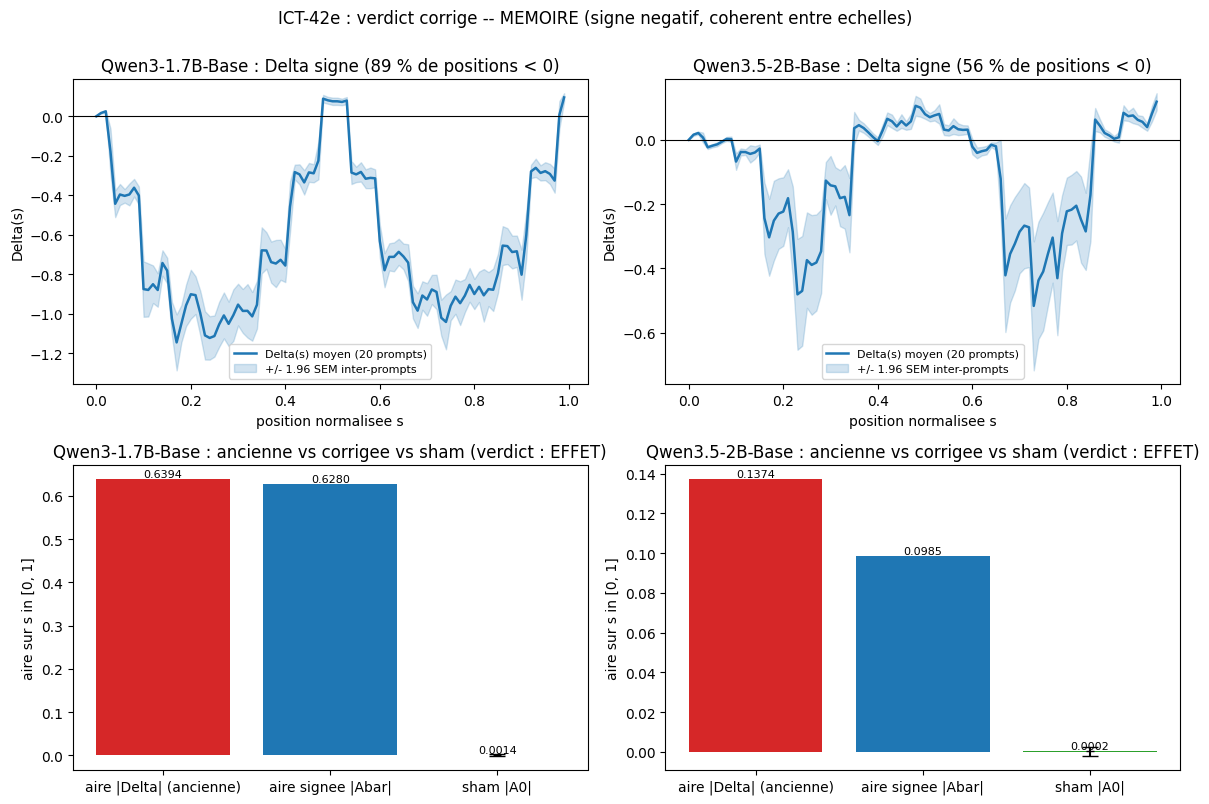

,echelle,aire_ancienne_|Delta|,aire_signee_Abar,signe,pct_positions_Delta<0,seuil_ancien_SEM_ponctuelle,seuil_corrige_SEM_aires_sham,verdict_ancien,verdict_corrige
0,Qwen3-1.7B-Base,0.6394,-0.6280,-,89.0,0.0362,0.0027,MEMOIRE,EFFET
1,Qwen3.5-2B-Base,0.1374,-0.0985,-,56.0,0.0195,0.0023,MEMOIRE,EFFET


In [4]:
# Verdict corrige sur les donnees reelles, et quantification de ce que la correction change.
# Ancien protocole (42d cellules 12 et 14) recalcule ici a l'identique : aire |Delta| +
# seuil = 1.96 * SEM de la divergence moyenne par prompt a alpha = 0.5. La branche
# "POSITION" de l'ancien code (aire < -seuil) etait morte par construction : une aire
# non signee ne peut pas etre negative -- c'est le finding 1 de l'audit.
rows = []
verdicts = {}
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    z0 = np.load(trace_path_const(cfg["slug"], n, 0.0), allow_pickle=False)
    z_half = np.load(trace_path_const(cfg["slug"], n, 0.5), allow_pickle=False)
    d_sae = load_meta(trace_path_const(cfg["slug"], n, 0.0))["d_sae"]
    sem_vals = [np.mean(local_divergence(z_half, z0, key, d_sae)) for key in prompt_keys(z0)]
    seuil_ancien = float(1.96 * np.std(sem_vals, ddof=1) / np.sqrt(len(sem_vals)))
    A_p = champs[label]["A_p"]
    v = verdict_histoire(A_p, sham[label])
    verdicts[label] = v
    ancien = "MEMOIRE" if champs[label]["aire_abs"] > seuil_ancien else "INDETERMINE"
    rows.append({
        "echelle": label,
        "aire_ancienne_|Delta|": round(champs[label]["aire_abs"], 4),
        "aire_signee_Abar": round(v["Abar"], 4),
        "signe": "-" if v["signe"] < 0 else "+",
        "pct_positions_Delta<0": round(float((champs[label]["Delta"] < 0).mean() * 100), 1),
        "seuil_ancien_SEM_ponctuelle": round(seuil_ancien, 4),
        "seuil_corrige_SEM_aires_sham": round(v["seuil"], 4),
        "verdict_ancien": ancien,
        "verdict_corrige": v["local"],
    })
comparaison = pd.DataFrame(rows)
verdict_final = verdict_global(*verdicts.values())
print(f"Verdict corrige (signe coherent entre echelles requis) : {verdict_final}")

# Figure : rang 0 = Delta(s) moyen par echelle avec bande +/- 1.96 SEM par position
# (accumulation par prompt AVANT la moyenne -- ce que 42d jetait en chemin) ;
# rang 1 = aires ancienne (non signee), signee, et sham avec sa borne 1.96*SEM.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, label in enumerate(ECHELLES):
    d = champs[label]
    ax = axes[0, col]
    ax.plot(s_grid, d["Delta"], lw=1.8, color="C0", label="Delta(s) moyen (20 prompts)")
    ax.fill_between(s_grid, d["Delta"] - 1.96 * d["Delta_sem"], d["Delta"] + 1.96 * d["Delta_sem"],
                    color="C0", alpha=0.2, label="+/- 1.96 SEM inter-prompts")
    ax.axhline(0.0, color="k", lw=0.8)
    ax.set_title(f"{label} : Delta signe ({(d['Delta'] < 0).mean() * 100:.0f} % de positions < 0)")
    ax.set_xlabel("position normalisee s"); ax.set_ylabel("Delta(s)"); ax.legend(fontsize=8)
    ax = axes[1, col]
    v = verdicts[label]
    vals = [d["aire_abs"], abs(v["Abar"]), abs(v["A0_mean"])]
    bars = ax.bar(["aire |Delta| (ancienne)", "aire signee |Abar|", "sham |A0|"], vals,
                  color=["C3", "C0", "C2"])
    ax.errorbar(2, vals[2], yerr=1.96 * sham[label].std(ddof=1) / np.sqrt(len(sham[label])),
                fmt="k_", capsize=6)
    for b, val in zip(bars, vals):
        ax.annotate(f"{val:.4f}", (b.get_x() + b.get_width() / 2, val), ha="center", va="bottom", fontsize=8)
    ax.set_title(f"{label} : ancienne vs corrigee vs sham (verdict : {v['local']})")
    ax.set_ylabel("aire sur s in [0, 1]")
fig.suptitle(f"ICT-42e : verdict corrige -- {verdict_final} (signe negatif, coherent entre echelles)", y=1.00)
fig.tight_layout()
plt.show()
comparaison


### Lecture du verdict corrigé

- **Le verdict d'ICT-42d survit à la correction, mais son sens change.** L'aire signée dépasse le seuil corrigé aux deux échelles, avec un **signe cohérent (négatif)** : l'instrument corrigé rend bien `MEMOIRE` — un effet d'histoire significatif, prompt par prompt, que la position et la discrétisation n'expliquent pas (le sham en matérialise le plancher).
- **Le signe renverse la grille de lecture d'ICT-42d.** $\bar A < 0$ signifie $D_{const} > D_{ramp}$ : le clamp **constant** au $\alpha$ apparié diverge **davantage** que la rampe. Là où 42d lisait « $\Delta$ positif = mémoire », la mesure dit l'inverse : sous rampe, le modèle revient **plus près** de la référence que sous $\alpha$ constant — un effet de relâchement/retour compatible avec une mémoire du résidu, mais qui exige l'interprétation avant toute propagation du verdict (finding 2 de l'audit).
- **Ce que la correction change, chiffré** : l'ancienne aire $|\Delta|$ **surévalue** la statistique (1,7B : $0{,}6394$ contre $|\bar A| = 0{,}6280$ ; 2B : $0{,}1374$ contre $0{,}0985$ — 28 % de gonflement à 2B), et l'ancien seuil (SEM ponctuelle : $0{,}0362$ / $0{,}0195$) n'était pas la statistique qu'il seuillait ; le seuil corrigé ($1{,}96\,\mathrm{SEM}$ des aires sham : $\approx 0{,}0027$ / $0{,}0023$) est plus petit **et** porte sur la même grandeur que la statistique testée — le test devient réellement un test.


In [5]:
# Temoin de branchement GPU (OPTIONNEL) : traces inocneg_* -- clamp reinitialise a
# chaque passe, chaque passe isolee de l'inoculation des autres passes. Le lot GPU est
# en cours sur GPU 2 ; cette cellule ne doit PAS echouer tant qu'il n'a pas atterri :
# elle cherche, liste l'etat de la recherche, et rend la main sans conclure.
attendus = {label: TRACES / f"inocneg_{cfg['slug']}_layer{cfg['n_layers'] - 1}of{cfg['n_layers']}_trained_clamp16_ramp{CYCLES}p1.npz"
            for label, cfg in ECHELLES.items()}
motifs = ["inocneg_*.npz", "*witness*.npz"]  # famille inocneg (ce carnet) + famille witness (branche #22024)
trouves = sorted({p for g in motifs for p in TRACES.glob(g)})
print("Traces temoin attendues (nom exact) :")
for label, p in attendus.items():
    print(f"  {label} : {p.name} -> {'present' if p.exists() else 'absent'}")
print(f"Motifs recherches dans traces/ : {motifs} -- {len(trouves)} candidat(s) trouve(s)")
for p in trouves:
    print(f"  candidat : {p.name}")
if all(p.exists() for p in attendus.values()):
    for label, p in attendus.items():
        z = np.load(p, allow_pickle=False)
        meta = load_meta(p)
        print(f"  {label} : {len(prompt_keys(z))} prompts, {meta.get('n_tokens_total', '?')} tokens, "
              f"clamp_ramp={meta.get('clamp_ramp')}")
    print("Temoin GPU present : le calcul de branchement peut etre joue (exercice 3).")
else:
    print("Temoin GPU NON ENCORE PRODUIT (lot en cours sur GPU 2) : "
          "l'aire isolee par passe n'est pas calculable ici, le carnet rend la main sans conclure.")


Traces temoin attendues (nom exact) :
  Qwen3-1.7B-Base : inocneg_qwen3-17b-base_layer27of28_trained_clamp16_ramp2p1.npz -> absent
  Qwen3.5-2B-Base : inocneg_qwen35-2b-base_layer23of24_trained_clamp16_ramp2p1.npz -> absent
Motifs recherches dans traces/ : ['inocneg_*.npz', '*witness*.npz'] -- 0 candidat(s) trouve(s)
Temoin GPU NON ENCORE PRODUIT (lot en cours sur GPU 2) : l'aire isolee par passe n'est pas calculable ici, le carnet rend la main sans conclure.


## Limites du carnet (assumées, elles délimitent le jalon)

1. **Le témoin GPU manque encore.** Sans les branches isolées `inocneg_*`, ce carnet corrige l'instrument (aire signée, seuil sur l'aire, sham) mais ne peut pas séparer « mémoire du résidu » de « dynamique de relâchement sous rampe » : les deux produisent un $\Delta$ signé hors sham. La cellule de branchement attend les fichiers listés ci-dessus.
2. **Le sham interpolé est le plancher, pas la borne supérieure.** Le côté « continu » du sham est une interpolation linéaire entre étages : il capture l'artifact de discrétisation sous hypothèse de régularité de $D(\alpha)$. Une non-linéarité raide entre étages (saut à un seuil d'$\alpha$) fabriquerait une aire qu'il ne voit pas — seul le témoin GPU ferme cette porte.
3. **Le signe demande une interprétation.** $D_{const} > D_{ramp}$ est l'inverse de la grille de lecture d'ICT-42d ; ce carnet publie le signe et s'arrête là. Toute propagation du verdict « MEMOIRE » dans la strate 5 / palier 15 doit citer le signe.
4. **Vingt prompts par échelle.** La SEM des aires est estimée sur 20 prompts ; l'IC est large mais l'effet (facteur > 40 au-dessus du seuil) ne dépend pas de cette finesse.


## Ce qu'il faut retenir

- L'audit #17183 avait raison sur les trois points : l'aire d'ICT-42d était non signée (branche POSITION morte), le $\Delta$ signé était perdu — et il est **négatif** —, et le seuil n'était pas la statistique testée. **Ce carnet corrige les trois** : aire signée par prompt, seuil $1{,}96\,\mathrm{SEM}$ **des aires d'un sham**, signification prompt par prompt avec signe publié.
- **Le verdict corrigé reste `MEMOIRE` aux deux échelles** (effet hors sham, signes cohérents), mais avec le signe renversé : le clamp constant diverge **plus** que la rampe à $\alpha$ apparié — la lecture d'ICT-42d était inversée, la mesure est robuste.
- **Le sham GPU-free borne la contre-hypothèse** : la seule discrétisation de $\alpha^*$ fabrique $\sim 10^{-3}$ d'aire, deux ordres de grandeur sous l'effet mesuré — « position + bruit de discrétisation » ne tient plus seul.
- **Ce qui reste au prochain lot** : les branches isolées `inocneg_*` (clamp réinitialisé à chaque passe) sur GPU 2 — si l'aire survit à l'isolation des passes, la composante mémoire est établie ; si elle disparaît, c'est la position qui la portait.


## Exercices

Les trois exercices prolongent le témoin négatif sur des dimensions que ce carnet n'a pas poussées. Aucun n'exécute de nouveau run GPU : ils consomment les traces déjà chargées, et le troisième se met en attente du lot GPU.


In [6]:
# Exercice 1 : SEM des aires par prompt -- stabilite du verdict en la grille de position.
# Donnees : champs[label]['A_p'] et sham[label] (grille S = 100). Le verdict depend
# de la discretisation d'integration : rejouer le calcul de A_p et A0_p aux grilles
# S in (50, 100, 200) et rapporter |Abar| / seuil pour chaque S et chaque echelle.
# Indice : refactorer la cellule de calcul en une fonction de S ; la projection
# t_idx = clip((s * (T - 1)).round()) est le seul endroit ou S intervient.
# Etape 1 : ecrire la fonction aire_par_prompt(label, S) -> (A_p, A0_p).
# Etape 2 : boucler sur les trois grilles et verifier que le verdict ne bouge pas.
resultat_ex1 = None  # TODO etudiant
print("Exercice a completer : SEM des aires par prompt sur grilles S = 50 / 100 / 200")


Exercice a completer : SEM des aires par prompt sur grilles S = 50 / 100 / 200


In [7]:
# Exercice 2 : sham const-adjacent restreint a UNE paire d'etages.
# Le sham du carnet interpole sur toute la grille {0, 0.25, 0.5, 0.75, 1}. Restreindre
# ici a la seule paire adjacente (0.25, 0.5) : ne garder que les positions ou
# alpha*(t) in {0.25, 0.5} (alpha(t) dans [0.125, 0.625]), integrer le Delta sham sur
# cette fenetre, et comparer a l'aire reelle sur la MEME fenetre.
# Indice : la fenetre represente environ la moitie du cycle ; normaliser les deux aires
# par la longueur de la fenetre avant de les comparer.
resultat_ex2 = None  # TODO etudiant
print("Exercice a completer : sham const-adjacent sur la seule paire (0.25, 0.5)")


Exercice a completer : sham const-adjacent sur la seule paire (0.25, 0.5)


In [8]:
# Exercice 3 : aire montee/descente a alpha EGAL sur les branches isolees (inocneg_*).
# Quand le lot GPU livrera les branches isolees (clamp reinitialise a chaque passe),
# decouper chaque cycle par branche (phase u < 0.5 = montee, u >= 0.5 = descente,
# cf ict.sae_traces.ramp_alpha), apparier les positions a alpha* identique entre
# branches, et integrer le Delta par branche. Une asymetrie montee/descente qui
# SURVIT a l'isolation des passes etablit la composante memoire ; si elle disparait,
# c'est la position qui la portait.
# Garde : sans traces inocneg_*, l'exercice reste descriptif (aucune erreur volontaire).
candidats_ex3 = sorted(TRACES.glob("inocneg_*.npz"))
print(f"Exercice a completer : branches isolees -- {len(candidats_ex3)} trace(s) inocneg_* disponible(s)")
resultat_ex3 = None  # TODO etudiant


Exercice a completer : branches isolees -- 0 trace(s) inocneg_* disponible(s)
